In [51]:
import numpy as np
import matplotlib.pyplot as plt

# (i) Random walk simulation
We simulate walks with 100, 1000, and 10000 steps.

# (i) Random walk simulation
We simulate walks with 100, 1000, and 10000 steps.

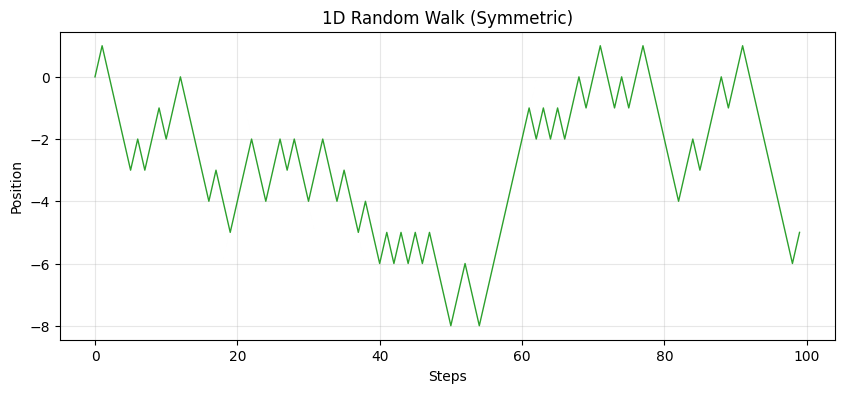

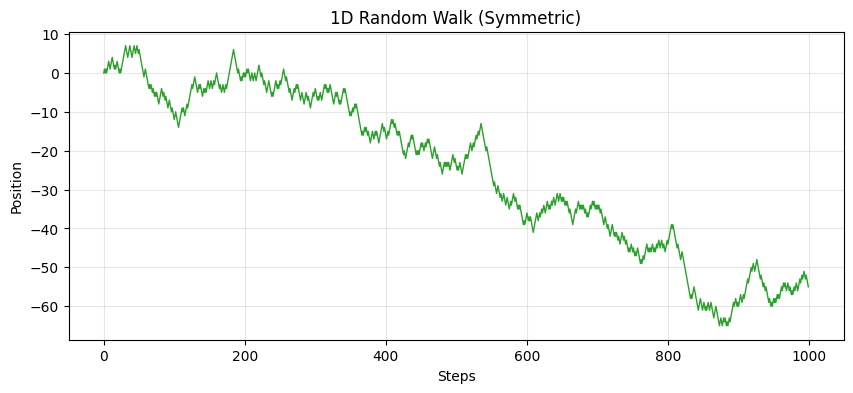

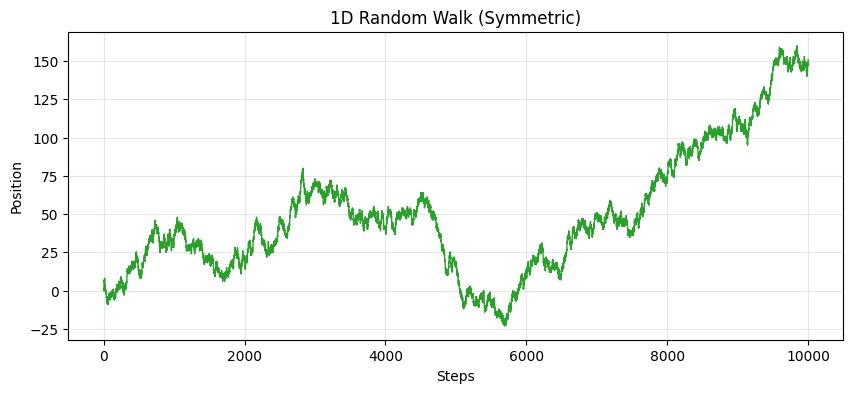

In [52]:
def path(steps):
    origin = 0       
    step_set = np.array([-1, 1])
    random_steps = np.random.choice(step_set, size=steps-1) #the default of np.random.choice is uniform so this is symmetric
    return np.concatenate([[origin], np.cumsum(random_steps)])

def viz(path):
    plt.figure(figsize=(10, 4))
    plt.plot(path, color='#2ca02c', linewidth=1)
    plt.title("1D Random Walk (Symmetric)")
    plt.xlabel("Steps")
    plt.ylabel("Position")
    plt.grid(True, alpha=0.3)
    plt.show()

viz(path(100))
viz(path(1000))
viz(path(10000))

# (ii) Averaging over many walks
The first moment does not appear to depend on t, but the second moment (MSD) appears to increase linearly with t, converging to a linear function of t as we increase the number of walks being averaged. Graphs of the moments are given for 100, 1000, and 10000 walk averages.

# (ii) Averaging over many walks
The first moment does not appear to depend on t, but the second moment (MSD) appears to increase linearly with t, converging to a linear function of t as we increase the number of walks being averaged. Graphs of the moments are given for 100, 1000, and 10000 walk averages.

In [53]:
def ensemble(size, steps):
    ensemble = np.zeros((size, steps))
    for i in range(size):
        ensemble[i] = path(steps)
    return ensemble

def mom1(ensemble):
    return np.mean(ensemble, axis=0)

def mom2(ensemble):
    return np.mean(np.square(ensemble), axis=0)

In [89]:
def ensemble(size, steps):
    ensemble = np.zeros((size, steps))
    for i in range(size):
        ensemble[i] = path(steps)
    return ensemble

def mom1(ensemble):
    return np.mean(ensemble, axis=0)

def mom2(ensemble):
    return np.mean(np.square(ensemble), axis=0)

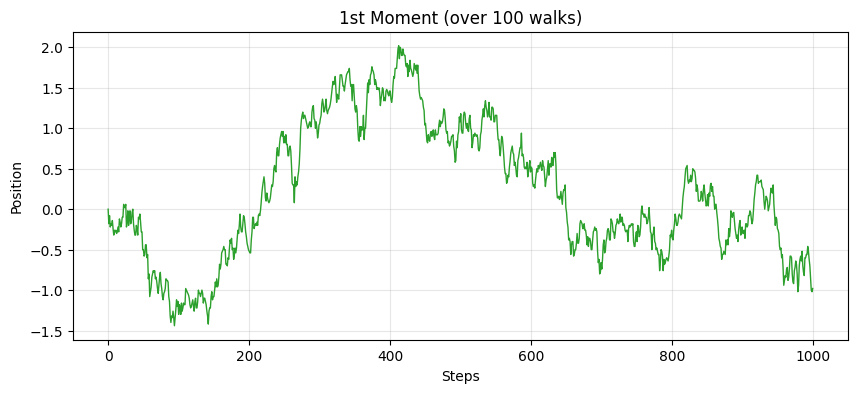

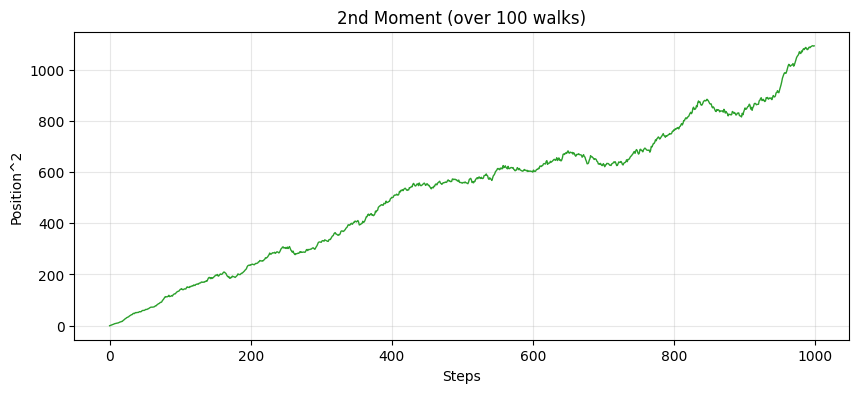

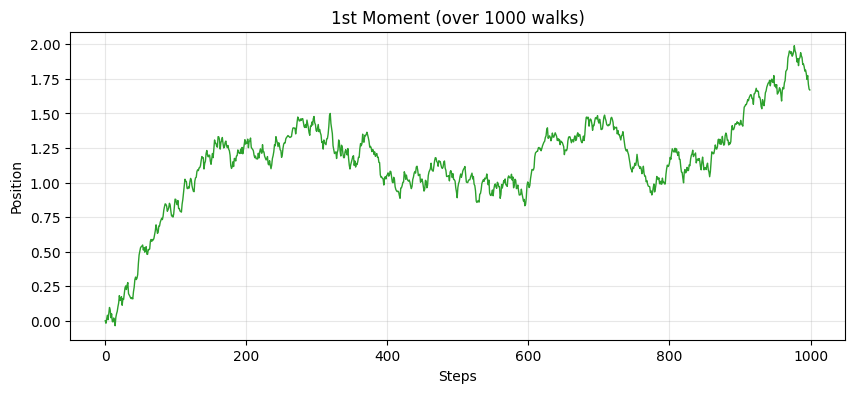

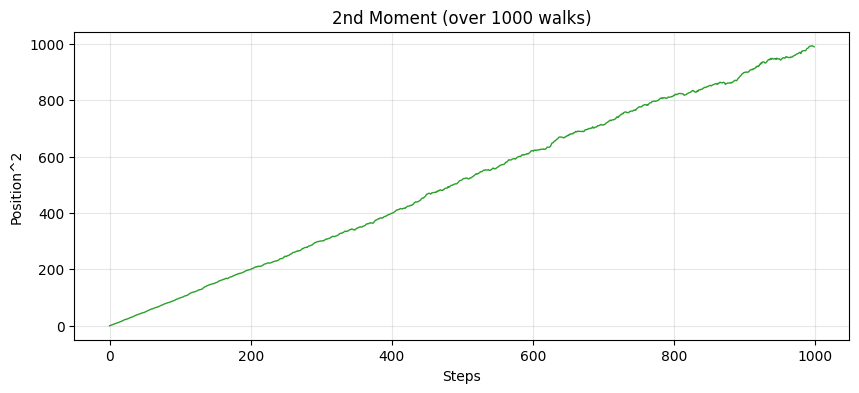

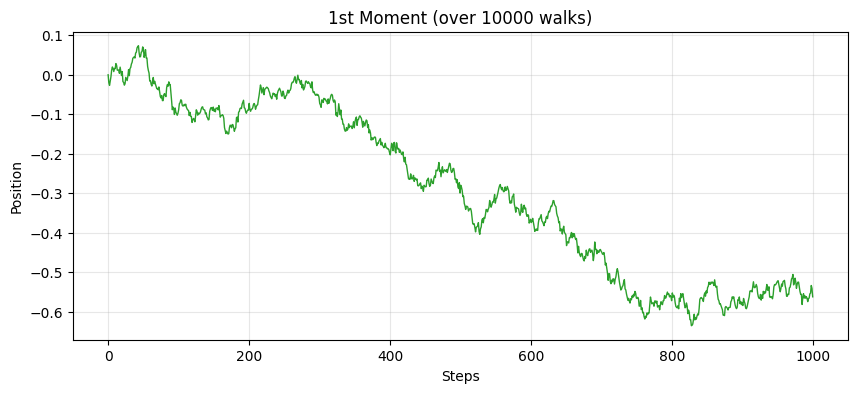

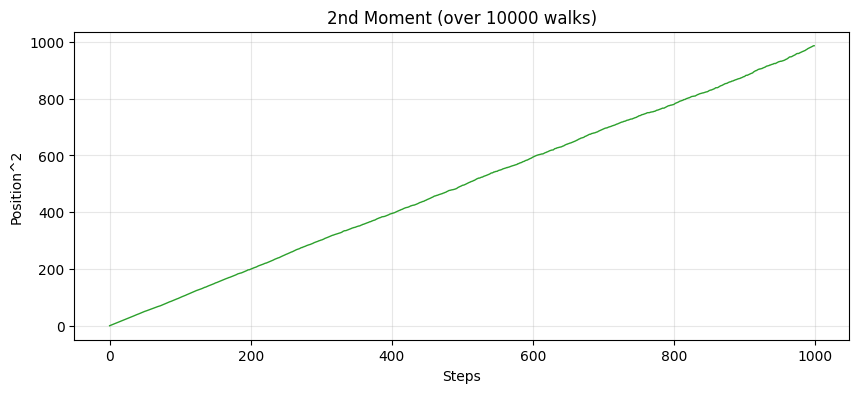

In [92]:
def vizmoms(ens):
    m1 = mom1(ens)
    m2 = mom2(ens)
    plt.figure(figsize=(10, 4))
    plt.plot(m1, color='#2ca02c', linewidth=1)
    plt.title("1st Moment (over "+str(np.size(ens,0))+" walks)")
    plt.xlabel("Steps")
    plt.ylabel("Position")
    plt.grid(True, alpha=0.3)
    plt.show()
    plt.figure(figsize=(10, 4))
    plt.plot(m2, color='#2ca02c', linewidth=1)
    plt.title("2nd Moment (over "+str(np.size(ens,0))+" walks)")
    plt.xlabel("Steps")
    plt.ylabel("Position^2")
    plt.grid(True, alpha=0.3)
    plt.show()

ens2 = ensemble(100, 1000)
vizmoms(ens2)
ens3 = ensemble(1000, 1000)
vizmoms(ens3)
ens4 = ensemble(10000, 1000)
vizmoms(ens4)

# (iii) Comparison to normal
The distribution is approximately a bell curve. It looks very similar to the sampled histograms, as shown below.

# (iii) Comparison to normal
The distribution is approximately a bell curve. It looks very similar to the sampled histograms, as shown below.

# (iii) Comparison to normal
The distribution is approximately a bell curve. It looks very similar to the sampled histograms, as shown below.

Text(0.5, 0.98, 'Histograms for final positions of 10000 walks and sampled values')

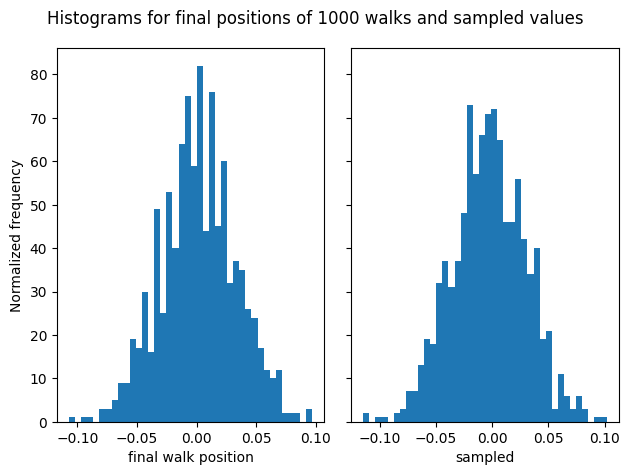

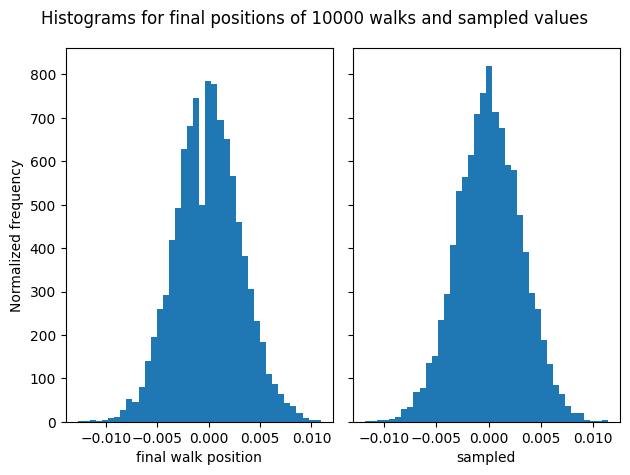

In [93]:
rng = np.random.default_rng(19680801)

fin3 = 0.001*ens3[:,-1]
fin3mean = np.mean(fin3)
fin3std = np.std(fin3)
dist3 = rng.standard_normal(1000)*fin3std-fin3mean
fig, axs = plt.subplots(1, 2, sharey=True, tight_layout=True)
axs[0].hist(fin3, bins=40)
axs[1].hist(dist3, bins=40)
axs[0].set_xlabel("final walk position")
axs[1].set_xlabel("sampled")
axs[0].set_ylabel("Normalized frequency")
fig.suptitle("Histograms for final positions of 1000 walks and sampled values")

fin4 = 0.0001*ens4[:,-1]
fin4mean = np.mean(fin4)
fin4std = np.std(fin4)
dist4 = rng.standard_normal(10000)*fin4std-fin4mean
fig, axs = plt.subplots(1, 2, sharey=True, tight_layout=True)
axs[0].hist(fin4, bins=40)
axs[1].hist(dist4, bins=40)
axs[0].set_xlabel("final walk position")
axs[1].set_xlabel("sampled")
axs[0].set_ylabel("Normalized frequency")
fig.suptitle("Histograms for final positions of 10000 walks and sampled values")